# ✅ Step 1 — Check Your Hardware

We verify the environment so you know:

- Whether a GPU is available  
- CPU details  
- Expected performance characteristics  

This helps you understand how your training will behave on Kaggle.

In [1]:
!nvidia-smi

/bin/bash: line 1: nvidia-smi: command not found


In [2]:
!cat /proc/cpuinfo | head -n 20

processor	: 0
vendor_id	: GenuineIntel
cpu family	: 6
model		: 79
model name	: Intel(R) Xeon(R) CPU @ 2.20GHz
stepping	: 0
microcode	: 0xffffffff
cpu MHz		: 2199.998
cache size	: 56320 KB
physical id	: 0
siblings	: 4
core id		: 0
cpu cores	: 2
apicid		: 0
initial apicid	: 0
fpu		: yes
fpu_exception	: yes
cpuid level	: 13
wp		: yes
flags		: fpu vme de pse tsc msr pae mce cx8 apic sep mtrr pge mca cmov pat pse36 clflush mmx fxsr sse sse2 ss ht syscall nx pdpe1gb rdtscp lm constant_tsc rep_good nopl xtopology nonstop_tsc cpuid tsc_known_freq pni pclmulqdq ssse3 fma cx16 pcid sse4_1 sse4_2 x2apic movbe popcnt aes xsave avx f16c rdrand hypervisor lahf_lm abm 3dnowprefetch pti ssbd ibrs ibpb stibp fsgsbase tsc_adjust bmi1 hle avx2 smep bmi2 erms invpcid rtm rdseed adx smap xsaveopt arat md_clear arch_capabilities


# ✅ Step 2 — Import Libraries & Configure Paths

We import:

- PyTorch (training)
- Torchvision (model + transforms)
- Pandas (CSV loading)
- COCO JSON parser
- Metrics (accuracy, AUC, F1,…)

We also set the dataset paths inside the Kaggle environment.

In [3]:
# =========================================================
# Imports
# =========================================================

import os
import json
import time
from datetime import datetime

import pandas as pd
from PIL import Image
from tqdm import tqdm
import matplotlib.pyplot as plt
import numpy as np

# PyTorch (deep learning framework)
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import efficientnet_b3, EfficientNet_B3_Weights

# Metrics from scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score, precision_score, recall_score

# =========================================================
# Dataset Paths — IMPORTANT:
# Kaggle mounts your dataset here automatically.
# =========================================================
DATASET_DIR = "/kaggle/input/competitions/1st-krones-vision-ai-challenge"
TRAIN_IMAGE_DIR = os.path.join(DATASET_DIR, "train_images")  # Folder with train images
TRAIN_CSV = os.path.join(DATASET_DIR, "train.csv")           # CSV containing class label for each image
TRAIN_JSON = os.path.join(DATASET_DIR, "train_annotations.json")  # COCO Annotations (including ROI)

# Folder to store logs, checkpoints, ONNX model
ARTIFACTS_DIR = "training_artifacts"

print("Dataset directory exists:", os.path.exists(DATASET_DIR))
print("Train images:", os.path.exists(TRAIN_IMAGE_DIR))
print("Train CSV:", os.path.exists(TRAIN_CSV))
print("Annotations JSON:", os.path.exists(TRAIN_JSON))

Dataset directory exists: True
Train images: True
Train CSV: True
Annotations JSON: True


# ✅ Step 3 — Load ROI (Region of Interest) From COCO JSON

The dataset includes COCO-style annotations.

- Category **22** marks the bounding box around the bottle region.
- We generate a dictionary:  
  **filename → ROI bounding box [x, y, w, h]**

Images without ROI are simply used uncropped.

In [4]:
def load_roi_map(annotation_file):
    """
    Loads the COCO annotation file and extracts ROI bounding boxes.
    Category_id == 22 contains the bottle ROI bounding boxes.
    Returns: { filename : [x, y, w, h] }
    """
    
    with open(annotation_file, "r") as f:
        data = json.load(f)

    # Map image_id -> filename for quick lookup
    img_lookup = {img["id"]: img["file_name"] for img in data["images"]}
    roi_map = {}

    # Iterate over all annotations
    for ann in data["annotations"]:
        if ann.get("category_id") == 22:         # ROI category
            fname = img_lookup[ann["image_id"]]  # find the filename
            roi_map[fname] = ann["bbox"]         # store bounding box

    print(f"✅ Loaded {len(roi_map)} ROI regions.")
    return roi_map

print("✅ ROI loader function defined successfully")

✅ ROI loader function defined successfully


# ✅ Step 4 — Build the PyTorch Dataset (with ROI Cropping)

The dataset:

- Loads image  
- Applies ROI cropping (if available)  
- Applies augmentations for training  
- Normalizes using ImageNet stats  
- Returns a tensor + label  

This works with both CPU & GPU.

In [5]:
class RoiDataset(Dataset):
    """
    PyTorch Dataset:
    - Loads image
    - Applies ROI cropping (if available)
    - Applies augmentations for training
    - Normalizes using ImageNet statistics
    """

    def __init__(self, df, roi_map, image_dir, train=True, image_size=(512, 512)):
        self.df = df
        self.roi_map = roi_map
        self.image_dir = image_dir
        self.train = train
        self.image_size = image_size

        # Augmentations for training
        self.train_tf = transforms.Compose([
            transforms.Resize(image_size),
            transforms.RandomHorizontalFlip(),
            transforms.RandomVerticalFlip(),                              # bottles have rotational symmetry
            transforms.RandomRotation(degrees=180),                       # same reason, full rotation makes sense for bottle bases
            transforms.ColorJitter(0.3, 0.3, 0.3, 0.15),                 # slightly stronger colour variation
            transforms.RandomAffine(0, translate=(0.1,0.1), fill=0),
            transforms.RandomGrayscale(p=0.05),                           # forces model to rely on shape not just colour
            transforms.ToTensor(),
            transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
        ])

        # Only resize + normalize for validation
        self.val_tf = transforms.Compose([
            transforms.Resize(image_size),
            transforms.ToTensor(),
            transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
        ])

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        # Load row (filename + label)
        row = self.df.iloc[idx]
        fname = row["image_id"]
        target = torch.tensor(row["target"], dtype=torch.float32)

        # Load image
        img = Image.open(os.path.join(self.image_dir, fname)).convert("RGB")

        # Crop ROI if available
        if fname in self.roi_map:
            x, y, w, h = self.roi_map[fname]
            img = img.crop((x, y, x + w, y + h))

        # Choose transforms based on training/validation mode
        img = self.train_tf(img) if self.train else self.val_tf(img)

        return img, target

print("✅ RoiDataset class defined successfully")

✅ RoiDataset class defined successfully


# ✅ Step 5 — Create the Model (EfficientNet-B3)

We use:

- ImageNet pretrained weights  
- Replace last layer with a **single binary output**  
- Predicts:  
  - `0` → Reusable  
  - `1` → Not Reusable  

In [6]:
def create_model():
    """
    Loads an EfficientNet-B3 model with pretrained ImageNet weights.
    Replaces the classification head with a single binary output.
    """
    model = efficientnet_b3(weights=EfficientNet_B3_Weights.DEFAULT)
    
    # Replace final FC layer with binary classifier
    in_features = model.classifier[1].in_features
    model.classifier[1] = nn.Linear(in_features, 1)

    return model

print("✅ Model creation function defined successfully")

✅ Model creation function defined successfully


# ✅ Step 6 — Training Loop

This function handles:

✅ Forward pass  
✅ Loss calculation  
✅ Backpropagation  
✅ Mixed Precision (AMP)  
✅ TQDM progress indicator  

In [7]:
# pass scheduler into train_one_epoch and step it every batch
def train_one_epoch(model, loader, optimizer, epoch, criterion, scaler, device, scheduler=None):
    """
    Performs one training epoch:
    - Forward pass
    - Loss computation
    - Backpropagation (with mixed precision)
    """
    model.train()
    total_loss = 0

    pbar = tqdm(loader, desc=f"Training Epoch {epoch}")

    for imgs, targets in pbar:
        imgs, targets = imgs.to(device), targets.to(device).unsqueeze(1)

        optimizer.zero_grad()

        # Mixed Precision forward pass
        with torch.amp.autocast(device_type="cuda", enabled=(device=="cuda")):
            logits = model(imgs)
            smooth = 0.1     # ADDED — smooth the targets slightly before computing loss
            targets_smooth = targets * (1 - smooth) + smooth / 2    # instead of hard 0/1 labels, use 0.1/0.9
            loss = criterion(logits, targets_smooth)    # this prevents the model from becoming overconfident
        # Backward pass + update weights
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        if scheduler is not None:                    # step scheduler every batch
            scheduler.step()
        total_loss += loss.item() * imgs.size(0)
        pbar.set_postfix({"Loss": f"{loss.item():.4f}"})

    avg_loss = total_loss / len(loader.dataset)
    print(f"✅ Epoch {epoch} — Avg Loss: {avg_loss:.4f}")
    return avg_loss


print("✅ Training loop function defined successfully")

✅ Training loop function defined successfully


# ✅ Step 7 — Validation Loop

Computes model performance using:

- ✅ Accuracy  
- ✅ AUC  
- ✅ F1-score  
- ✅ Precision  
- ✅ Recall  

In [8]:
def validate(model, loader, threshold=0.5, device="cuda"):
    """
    Runs validation:
    - Computes probabilities using sigmoid()
    - Applies threshold to convert to class labels
    - Computes accuracy, AUC, F1, precision, recall
    """
    model.eval()
    all_targets, all_probs = [], []

    pbar = tqdm(loader, desc="Validating")

    with torch.no_grad():
        for imgs, targets in pbar:
            imgs = imgs.to(device)
            targets = targets.to(device).unsqueeze(1)

            # Forward pass in mixed precision
            with torch.amp.autocast(device_type="cuda", enabled=(device=="cuda")):
                logits = model(imgs)

            probs = torch.sigmoid(logits)  # convert logits → probabilities

            all_probs.extend(probs.cpu().numpy())
            all_targets.extend(targets.cpu().numpy())

    # Convert probabilities to binary predictions
    bin_preds = [1 if p >= threshold else 0 for p in all_probs]

    return {
        "acc": accuracy_score(all_targets, bin_preds),
        "auc": roc_auc_score(all_targets, all_probs),
        "f1": f1_score(all_targets, bin_preds),
        "precision": precision_score(all_targets, bin_preds),
        "recall": recall_score(all_targets, bin_preds),
    }

print("✅ Validation function defined successfully")

✅ Validation function defined successfully


# ✅ Step 8 — Load the data and initialize the dataloaders

This:

1. Loads ROI map  
2. Reads CSV labels  
3. Splits into train/validation  
4. Initializes dataloaders

In [9]:
# Create output folder
os.makedirs(os.path.join(os.getcwd(), ARTIFACTS_DIR), exist_ok=True)
run_name = "run_" + datetime.now().strftime("%Y%m%d_%H%M")
run_dir = os.path.join(ARTIFACTS_DIR, run_name)
os.makedirs(run_dir, exist_ok=True)

# Hyperparameters
image_size = (512, 512)
batch_size = 32
workers = 4
num_epochs = 30  # moved here from model setup section

# Determine device (GPU preferred)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("✅ Using device:", device)

# Load ROI map
roi_map = load_roi_map(TRAIN_JSON)

# Load CSV labels
df = pd.read_csv(TRAIN_CSV)

# Optional: Limit dataset for fast testing/experimentation. (Set to None for full run).
LIMIT = None

if LIMIT is not None:
    # Subsamples the dataframe
    df = df.sample(LIMIT, random_state=42).reset_index(drop=True)

# Create train/validation split
train_df, val_df = train_test_split(df, test_size=0.1,
                                    stratify=df["target"], random_state=42)

# Build datasets + dataloaders
train_ds = RoiDataset(train_df, roi_map, TRAIN_IMAGE_DIR, train=True, image_size=image_size)
val_ds = RoiDataset(val_df, roi_map, TRAIN_IMAGE_DIR, train=False, image_size=image_size)

# Build dataloaders
train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=workers, pin_memory=True if torch.cuda.is_available() else False)
val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False, num_workers=workers, pin_memory=True if torch.cuda.is_available() else False)

✅ Using device: cpu
✅ Loaded 35342 ROI regions.


# ✅ Step 9 — Dataset Review & Visualization
Always visualize your data! Let's check a few crops out of the validation data stream to ensure our bounding boxes and augmentations processed correctly.

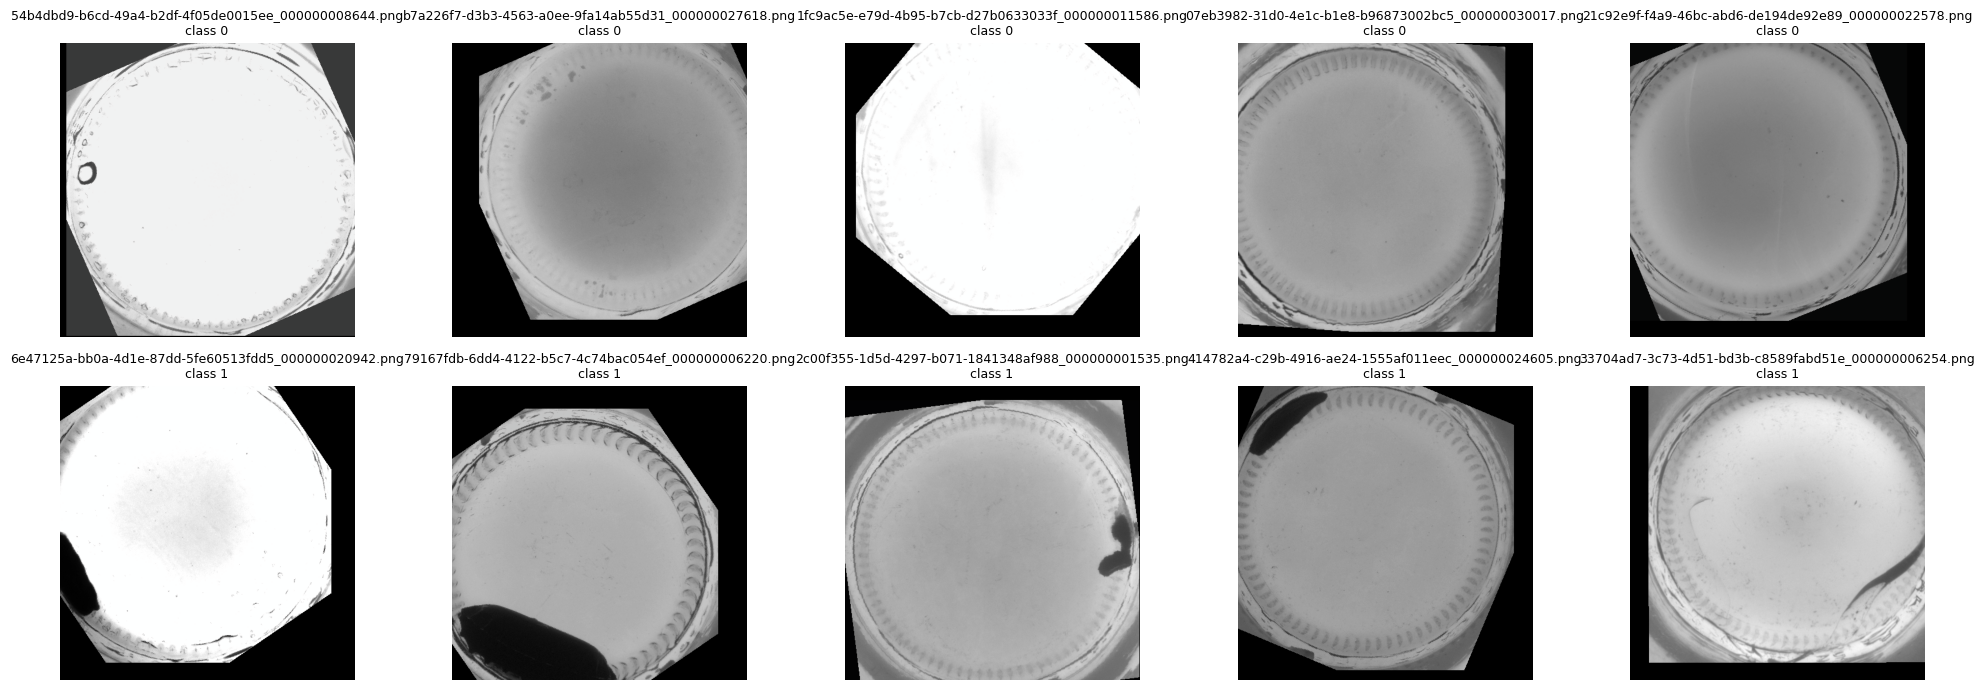

In [10]:
def show_samples(dataset, num_per_class=5):
    class_samples = {0: [], 1: []}

    # Collect samples: (image_tensor, label, filename)
    for idx in range(len(dataset)):
        img, label = dataset[idx]
        fname = dataset.df.iloc[idx]["image_id"]  # retrieve filename

        label = int(label.item())
        if len(class_samples[label]) < num_per_class:
            class_samples[label].append((img, fname))
        
        if len(class_samples[0]) >= num_per_class and len(class_samples[1]) >= num_per_class:
            break

    # Plot
    fig, ax = plt.subplots(2, num_per_class, figsize=(num_per_class * 4, 7))

    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    for cls in [0, 1]:
        for i, (img, fname) in enumerate(class_samples[cls]):
            img_np = img.permute(1, 2, 0).numpy()
            img_np = std * img_np + mean
            img_np = np.clip(img_np, 0, 1)

            ax[cls, i].imshow(img_np)
            ax[cls, i].set_title(f"{fname}\nclass {cls}", fontsize=9)
            ax[cls, i].axis("off")

    plt.tight_layout()
    plt.show()


show_samples(train_ds)

# ✅ Step 10 — Running the full training pipeline

1. Trains for `num_epochs` epochs  
2. Generates the artifacts in `training_artifacts/`:
   - `best_model.pth`
   - `latest_model.pth`
   - `model.onnx` ✅ required

## Approach Explanation

**Model Architecture**
We used EfficientNet-B3 as our base model, which was already pretrained on ImageNet. We swapped out its last layer with a single output so it predicts  one of two classes: 0 (Reusable) or 1 (Not Reusable).

**Key Design Decisions**
- ROI cropping: the annotations tell us exactly where the bottle is in each image, so we crop to that region before passing it to the model. This way the model focuses on the bottle and ignores the background.
- Frozen backbone: for the first 5 epochs we only trained the new output layer we added, and kept the rest of the model frozen. This is because the new layer starts with random weights and could mess up the pretrained weights if we trained everything at once from the start. At epoch 6 we unfreeze everything and train the full model.
- Label smoothing: instead of using hard labels of exactly 0 and 1, we softened them slightly to 0.05 and 0.95. This stops the model from becoming too overconfident in its predictions.
- Weighted loss: there are more good bottles than defective ones in the dataset, so we told the loss function to penalise the model more when it misses a defective bottle. This helps with the class imbalance.
- AdamW optimizer: similar to Adam but with an extra penalty for very large weights, which helps prevent overfitting.
- OneCycleLR scheduler: automatically adjusts the learning rate during training, starting slow, ramping up, then decreasing again. This generally leads to better results than a fixed learning rate.

**Augmentations**
During training we randomly flipped images horizontally and vertically, rotated them up to 180 degrees, applied slight colour changes, and occasionally converted images to grayscale. We chose these because bottle bases look the same from any angle, and the grayscale augmentation forces the model to learn from shape rather than just colour.

**Additional Data Used**
We used the provided COCO annotation file (train_annotations.json) to get the bounding boxes for ROI cropping. No outside datasets were used.

In [ ]:
# Initialize model + optimizer + scheduler
model = create_model().to(device)
# freeze all layers in the pretrained backbone first
for param in model.parameters():
    param.requires_grad = False

# unfreeze only the new classifier head
for param in model.classifier.parameters():
    param.requires_grad = True

print("✅ Backbone frozen — only classifier head is training")
# calculate class weights from your training data
num_pos = train_df["target"].sum()                    # number of defective bottles
num_neg = len(train_df) - num_pos                     # number of good bottles
pos_weight = torch.tensor([num_neg / num_pos]).to(device)  # ratio tells loss to penalise missing defects more
# pass the weight in so missing a defect costs more than a false alarm
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
# AdamW is Adam with proper weight decay, which reduces overfitting
# weight_decay adds a small penalty for large weights, keeping the model generalising better
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
# warmup period lets the model stabilise before the learning rate starts dropping
# without warmup, the first few epochs can be unstable because the new classifier head
# starts with random weights and can pull the pretrained weights in wrong directions
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=3e-4,epochs=num_epochs,steps_per_epoch=len(train_loader))
scaler = torch.amp.GradScaler(enabled=(device=="cuda"))

best_auc = 0.0

# -------------------------
# Training Loop
# -------------------------
for epoch in range(1, num_epochs + 1):

    if epoch == 6:  # freeze/unfreeze from Change 6
        for param in model.parameters():
            param.requires_grad = True
        print("✅ All layers unfrozen — full network is now training")
        
    train_one_epoch(model, train_loader, optimizer, epoch, criterion, scaler, device, scheduler) # scheduler passed in
    metrics = validate(model, val_loader, threshold=0.5, device=device)
    # scheduler.step() is removed — it now happens inside train_one_epoch after every batch

    print(f"Epoch {epoch} — AUC: {metrics['auc']:.4f} | F1: {metrics['f1']:.4f}")

    # Save best checkpoint
    if metrics["auc"] > best_auc:
        best_auc = metrics["auc"]
        torch.save(model.state_dict(), os.path.join(run_dir, "best_model.pth"))
        print("✅ New Best Model Saved!")

    # Always save latest checkpoint
    torch.save(model.state_dict(), os.path.join(run_dir, "latest_model.pth"))

Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b3_rwightman-b3899882.pth


100%|██████████| 47.2M/47.2M [00:00<00:00, 147MB/s] 


✅ Backbone frozen — only classifier head is training


Training Epoch 1:   0%|          | 0/994 [00:00<?, ?it/s]

## ✅ Step 11 — Install ONNXScript (if not already installed)


For evaluation (as shown in the **starter evaluation notebook**), the model **must be provided in ONNX format**.

- If you **train the model in Kaggle**, you may install **ONNXScript** and export to ONNX directly *(requires internet access)*.
- If you **train outside Kaggle** or prefer to use your **own hardware**, you can export the model to **ONNX yourself** and then **upload the `.onnx` file to Kaggle**.

✅ Either approach is fine — the key requirement is having a **model in ONNX format for evaluation**.

In [ ]:
!pip install onnxscript

# ✅ Step 12 — Exporting the Model to ONNX Format (Required!)

Your model MUST be exported to ONNX so it can be evaluated
in the Official Evaluation Notebook.

⚠️ Do not remove this step. 


You may see several **warnings** during export (e.g., about missing type
annotations or internal PyTorch exporter messages).  


✅ **If you see `Saved ONNX model to ...` the export was successful.**

In [ ]:
def export_to_onnx(model, image_size, save_path):
    """
    Exports the trained PyTorch model to ONNX format.
    Required for the official evaluation notebook.
    """
    
    model.eval()

    # Dummy input needed for ONNX tracing
    dummy = torch.randn(1, 3, image_size[0], image_size[1]).to(next(model.parameters()).device)

    torch.onnx.export(
        model, dummy, save_path,
        input_names=["input"],     # names used in ONNX Runtime
        output_names=["logits"],
        opset_version=18
    )

    print(f"✅ Saved ONNX model to {save_path}")

# Export best ONNX model
model.load_state_dict(torch.load(os.path.join(run_dir, "best_model.pth")))
export_to_onnx(model, image_size, os.path.join(run_dir, "model.onnx"))

In [ ]:
import glob
print(glob.glob("training_artifacts/**/*model.onnx", recursive=True))